# IDX Exchange DS Internship - Week Five -  Additional Models

* Try Decision Tree and Random Forest regressors.
* Compare their test R² against baseline.
* Document model behavior (strengths/weaknesses)

In [1]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error

import matplotlib.pyplot as plt

## Import Data

In [6]:
# Read in the training and test sets created earlier

train_and_val = pd.read_csv("week_3_train.csv")
testing = pd.read_csv("week_3_test.csv")

In [7]:
# Create a validation set out of the training data

# Training Set: January 2024 - February 2026
# Validation Set: March 2026
# Test Set: April 2026

training = train_and_val[~(train_and_val["PropertyMonth"] == "2026-03-01")]
validation = train_and_val[train_and_val["PropertyMonth"] == "2026-03-01"]

print(train_and_val.shape, training.shape, validation.shape)

(265391, 54) (255097, 54) (10294, 54)


In [2]:
def median_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.median(np.abs((y_true - y_pred) / y_true))

def metrics(y_true, y_pred):
    # Note: you have to undeo the log transform on ClosePrice by using np.exp()!
    y_true = np.exp(y_true)
    y_pred = np.exp(y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    mdape = median_absolute_percentage_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    return r2, mape * 100, mdape * 100, mae

def metrics_no_log(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    mdape = median_absolute_percentage_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    return r2, mape * 100, mdape * 100, mae

def metric_df(r2_train, mape_train, mdape_train, mae_train,
              r2_val, mape_val, mdape_val, mae_val,
              r2_test, mape_test, mdape_test, mae_test):
    data = {"r2": [r2_train, r2_val, r2_test],
            "MAPE": [mape_train, mape_val, mape_test],
            "MdAPE": [mdape_train, mdape_val, mdape_test],
            "MAE": [f"${round(mae_train, 2)}", f"${round(mae_val, 2)}", f"${round(mae_test, 2)}"]}
    df = pd.DataFrame(data)
    df.index = ["Train Set", "Validation Set", "Test Set"]
    return df

In [9]:
# Columns not being used: "ListingKey", "ListingId", "ClosePrice", "ListOfficeName", "CountyOrParish", "YearBuilt",
#         "City", "HighSchoolDistrict", "PostalCode", "LivingArea", "LotSizeSquareFeet", "AssociationFee", "StateOrProvince_CO",
#         "StateOrProvince_ME", "StateOrProvince_NV", "StateOrProvince_NV", "StateOrProvince_OS", "StateOrProvince_TN"

common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog",
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "StateOrProvince_AZ", "StateOrProvince_CA",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "PropertyMonth", "ClosePriceLog"]

# The x_train window will be set per model, so don't define it here

x_val = validation[["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "StateOrProvince_AZ", "StateOrProvince_CA",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc"]]  
y_val = validation["ClosePriceLog"]


x_test = testing[["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "StateOrProvince_AZ", "StateOrProvince_CA",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc"]]
y_test = testing["ClosePriceLog"]

## Decision Trees

### Model One: Baseline Decision Tree

#### Train Set: January 2024 - February 2026

In [54]:
# Use the full set of available months (26 months)

x_train = training[common_cols].drop(columns = ["PropertyMonth", "ClosePriceLog"])
y_train = training["ClosePriceLog"]

In [55]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

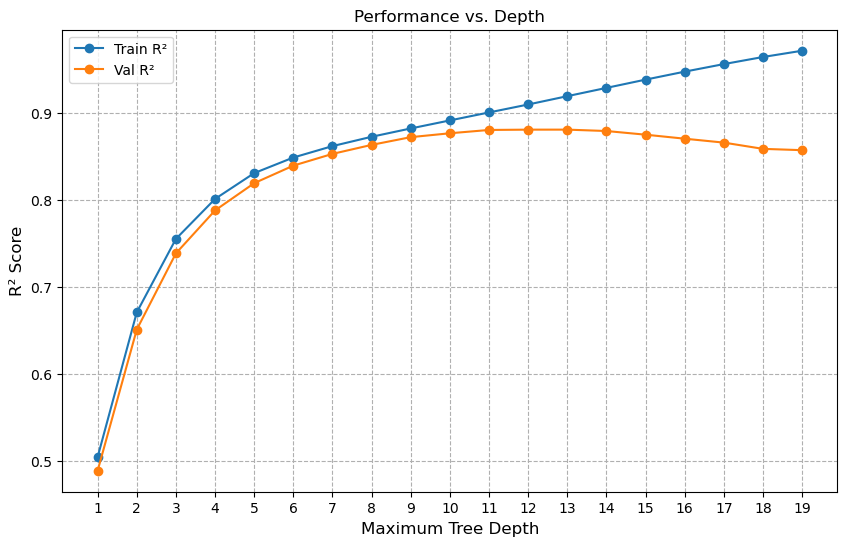

In [56]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [57]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 13


In [58]:
model_one_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_one_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.895686,10.549802,7.738357,$119924.56
Validation Set,0.843640,12.649337,8.971638,$145858.82
Test Set,0.859194,12.040223,8.602571,$143806.39


#### Train Set: February 2025 - February 2026

In [59]:
# Shorten the training window to the year preceding the validation set (12 months)

past_limit = pd.to_datetime("2025-01-01")
present_limit = pd.to_datetime("2026-02-01")

x_train_with_month = training[common_cols]
x_train_with_month.loc[:, "PropertyMonth"] = pd.to_datetime(x_train_with_month["PropertyMonth"])
x_train = x_train_with_month[(x_train_with_month["PropertyMonth"] >= past_limit) & (x_train_with_month["PropertyMonth"] <= present_limit)]
y_train = x_train["ClosePriceLog"]
x_train = x_train.drop(columns = ["PropertyMonth", "ClosePriceLog"])

In [60]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

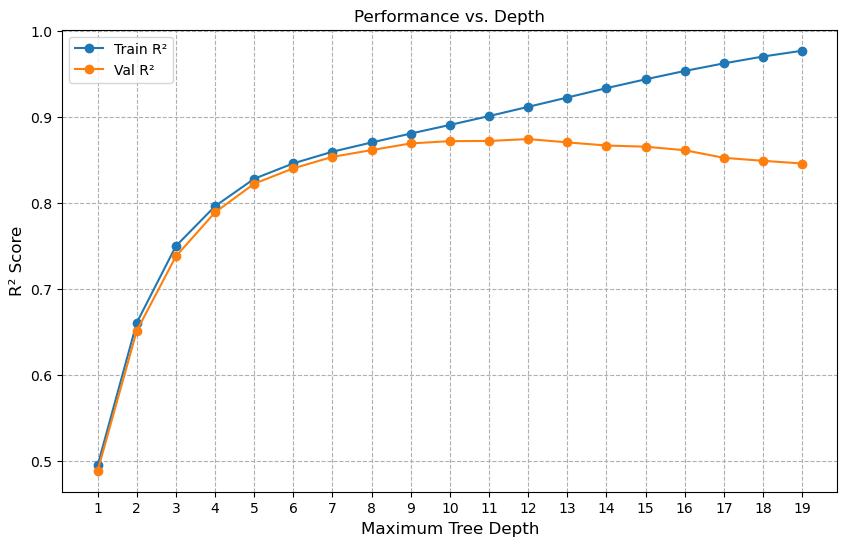

In [61]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [62]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 12


In [63]:
model_one_v2 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_one_v2

,r2,MAPE,MdAPE,MAE
Train Set,0.887054,11.007249,8.128804,$124083.87
Validation Set,0.832028,13.124094,9.393903,$151338.84
Test Set,0.846084,12.626839,9.156619,$150977.15


#### Train Set: July 2024 - February 2026

In [65]:
# Set the training window to 20 months preceding the validation set

past_limit = pd.to_datetime("2024-06-01")
present_limit = pd.to_datetime("2026-02-01")

x_train_with_month = training[common_cols]
x_train_with_month.loc[:, "PropertyMonth"] = pd.to_datetime(x_train_with_month["PropertyMonth"])
x_train = x_train_with_month[(x_train_with_month["PropertyMonth"] >= past_limit) & (x_train_with_month["PropertyMonth"] <= present_limit)]
y_train = x_train["ClosePriceLog"]
x_train = x_train.drop(columns = ["PropertyMonth", "ClosePriceLog"])

In [66]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

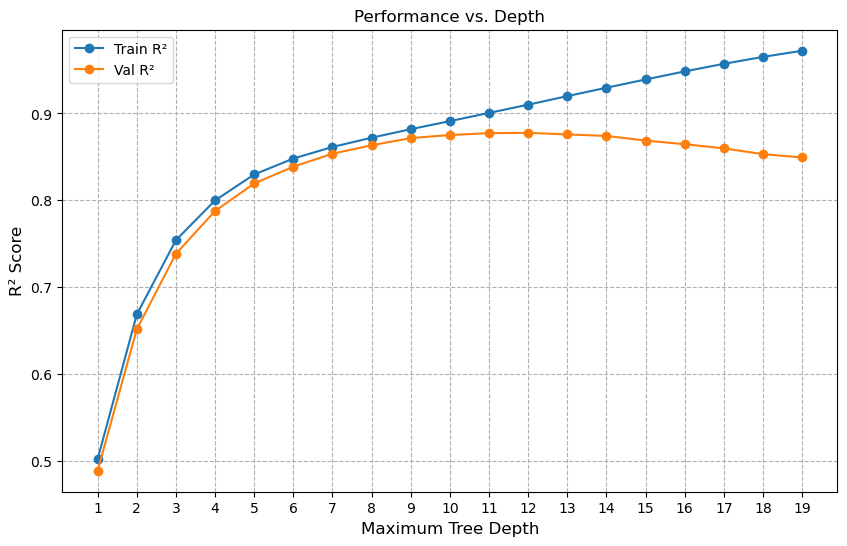

In [67]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [68]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 12


In [69]:
model_one_v3 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_one_v3

,r2,MAPE,MdAPE,MAE
Train Set,0.884395,11.132382,8.231073,$126586.16
Validation Set,0.840509,12.851287,9.185967,$147602.11
Test Set,0.856850,12.381577,8.889899,$146905.04


### Model Two: Outlier Winsorized Decision Tree

#### Train Set: January 2024 - February 2026

In [73]:
# ClosePriceLog had its largest values dropped during preprocessing
# Winsorize the other large numeric variables to see if this improves performance
# Columns to winsorize: "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog"

winz_tv = train_and_val.copy()
winz_test = testing.copy()

upper_bound = winz_tv["LivingAreaLog"].quantile(0.95)
winz_tv["LivingAreaLog"] = winz_tv["LivingAreaLog"].clip(lower=0, upper=upper_bound)
winz_test["LivingAreaLog"] = winz_test["LivingAreaLog"].clip(lower=0, upper=upper_bound)

upper_bound = winz_tv["AssociationFeeLog"].quantile(0.95)
winz_tv["AssociationFeeLog"] = winz_tv["AssociationFeeLog"].clip(lower=0, upper=upper_bound)
winz_test["AssociationFeeLog"] = winz_test["AssociationFeeLog"].clip(lower=0, upper=upper_bound)

upper_bound = winz_tv["LotSizeSquareFeetLog"].quantile(0.95)
winz_tv["LotSizeSquareFeetLog"] = winz_tv["LotSizeSquareFeetLog"].clip(lower=0, upper=upper_bound)
winz_test["LotSizeSquareFeetLog"] = winz_test["LotSizeSquareFeetLog"].clip(lower=0, upper=upper_bound)

In [84]:
training_winz = winz_tv[~(winz_tv["PropertyMonth"] == "2026-03-01")]
validation_winz = winz_tv[winz_tv["PropertyMonth"] == "2026-03-01"]

common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog",
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "StateOrProvince_AZ", "StateOrProvince_CA",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc"]

x_train = training_winz[common_cols]
y_train = training_winz["ClosePriceLog"]

x_val = validation_winz[common_cols]  
y_val = validation_winz["ClosePriceLog"]

x_test = winz_test[common_cols]
y_test = winz_test["ClosePriceLog"]

In [85]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

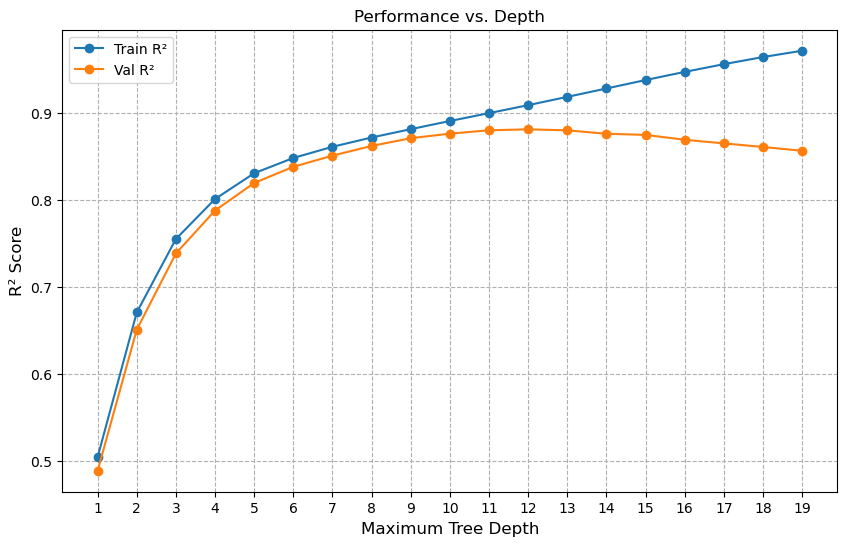

In [88]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [86]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 12


In [87]:
model_two_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_two_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.880945,11.232682,8.257226,$128263.05
Validation Set,0.843571,12.706594,9.144713,$146312.31
Test Set,0.858909,12.196823,8.856502,$145625.93


### Model Three: BedBathRatio and PropertyAge

In [3]:
# In week six, a few features were added to help improve model performance
# Read in the training and test sets created in week six

train_and_val = pd.read_csv("feat_eng_train.csv")
testing = pd.read_csv("feat_eng_test.csv")

In [4]:
training = train_and_val[~(train_and_val["PropertyMonth"] == "2026-03-01")]
validation = train_and_val[train_and_val["PropertyMonth"] == "2026-03-01"]

print(train_and_val.shape, training.shape, validation.shape)

(265314, 163) (255022, 163) (10292, 163)


In [5]:
common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "StateOrProvince_AZ", "StateOrProvince_CA",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "BedBathRatio", "PropertyAge"]

x_train = training[common_cols]
y_train = training["ClosePriceLog"]

x_val = validation[common_cols]  
y_val = validation["ClosePriceLog"]


x_test = testing[common_cols]
y_test = testing["ClosePriceLog"]

In [6]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

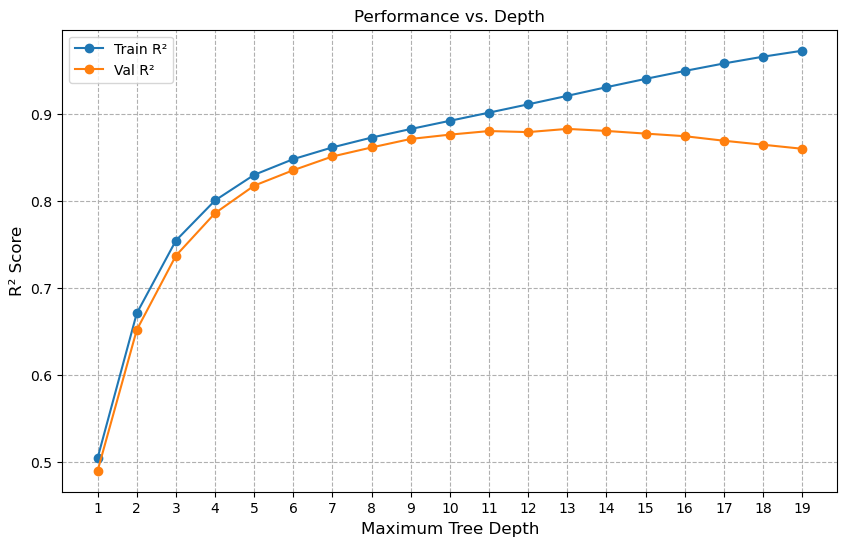

In [7]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [8]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 13


In [9]:
model_three = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_three

,r2,MAPE,MdAPE,MAE
Train Set,0.898101,10.453973,7.650121,$118603.67
Validation Set,0.845669,12.603380,9.004788,$145461.82
Test Set,0.860151,12.010818,8.598630,$143229.46


### Model Four: Improved School Districts

#### Both Counts and Percents

In [20]:
# During the week six feature engineering, the MLS data was joined with a California School District Area dataset
# That dataset contains school district names, as well as demographic data within that district
# This section will include both the percent and count columns for demographic information

common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "StateOrProvince_AZ", "StateOrProvince_CA",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "BedBathRatio", "PropertyAge",
            "DistrictName_elem_enc", "DistrictName_unif_enc", "DistrictName_high_enc",
            'EnrollTotal_high', 'EnrollCharter_high', 'EnrollNonCharter_high', 'AApct_high', 'AAcount_high', 'AIpct_high',
            'AIcount_high', 'ASpct_high', 'AScount_high', 'FIpct_high', 'FIcount_high', 'HIpct_high', 'HIcount_high', 'PIpct_high',
            'PIcount_high', 'WHpct_high', 'WHcount_high', 'MRpct_high', 'MRcount_high', 'NRpct_high', 'NRcount_high', 'ELpct_high',
            'ELcount_high', 'FOSpct_high', 'FOScount_high','HOMpct_high','HOMcount_high','MIGpct_high','MIGcount_high','SWDpct_high',
            'SWDcount_high','SEDpct_high','SEDcount_high', 'EnrollTotal_elem','EnrollCharter_elem','EnrollNonCharter_elem','AApct_elem',
            'AAcount_elem','AIpct_elem','AIcount_elem','ASpct_elem','AScount_elem','FIpct_elem','FIcount_elem','HIpct_elem','HIcount_elem',
            'PIpct_elem','PIcount_elem','WHpct_elem','WHcount_elem','MRpct_elem','MRcount_elem','NRpct_elem','NRcount_elem','ELpct_elem',
            'ELcount_elem','FOSpct_elem','FOScount_elem','HOMpct_elem','HOMcount_elem','MIGpct_elem','MIGcount_elem','SWDpct_elem',
            'SWDcount_elem','SEDpct_elem','SEDcount_elem','EnrollTotal_unif','EnrollCharter_unif','EnrollNonCharter_unif','AApct_unif',
            'AAcount_unif','AIpct_unif','AIcount_unif','ASpct_unif','AScount_unif','FIpct_unif','FIcount_unif','HIpct_unif','HIcount_unif',
            'PIpct_unif','PIcount_unif','WHpct_unif','WHcount_unif','MRpct_unif','MRcount_unif','NRpct_unif','NRcount_unif','ELpct_unif',
            'ELcount_unif','FOSpct_unif','FOScount_unif','HOMpct_unif','HOMcount_unif','MIGpct_unif','MIGcount_unif','SWDpct_unif',
            'SWDcount_unif','SEDpct_unif','SEDcount_unif']

x_train = training[common_cols]
y_train = training["ClosePriceLog"]

x_val = validation[common_cols]  
y_val = validation["ClosePriceLog"]

x_test = testing[common_cols]
y_test = testing["ClosePriceLog"]

In [21]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

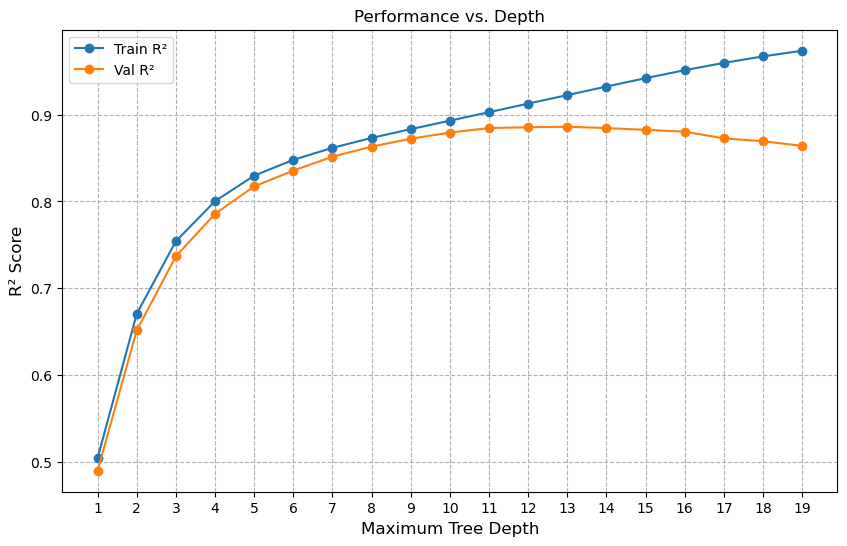

In [22]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [23]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 13


In [24]:
model_four_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_four_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.900648,10.300355,7.508349,$116822.07
Validation Set,0.850686,12.325717,8.831903,$142527.19
Test Set,0.864478,11.885169,8.386027,$141401.19


#### Only Percents

In [26]:
# Test if model performance changes when only the percent columns are used for demographic information

common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "StateOrProvince_AZ", "StateOrProvince_CA",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "BedBathRatio", "PropertyAge",
            "DistrictName_elem_enc", "DistrictName_unif_enc", "DistrictName_high_enc",
            'EnrollTotal_high', 'EnrollCharter_high', 'EnrollNonCharter_high', 'AApct_high', 'AIpct_high',
            'ASpct_high','FIpct_high','HIpct_high','PIpct_high',
            'WHpct_high','MRpct_high', 'NRpct_high', 'ELpct_high',
            'FOSpct_high', 'HOMpct_high','MIGpct_high','SWDpct_high',
            'SEDpct_high','EnrollTotal_elem','EnrollCharter_elem','EnrollNonCharter_elem','AApct_elem',
            'AIpct_elem','ASpct_elem','FIpct_elem','HIpct_elem',
            'PIpct_elem','WHpct_elem','MRpct_elem','NRpct_elem','ELpct_elem',
            'FOSpct_elem','HOMpct_elem','MIGpct_elem','SWDpct_elem',
            'SEDpct_elem','EnrollTotal_unif','EnrollCharter_unif','EnrollNonCharter_unif','AApct_unif',
            'AIpct_unif','ASpct_unif','FIpct_unif','HIpct_unif',
            'PIpct_unif','WHpct_unif','MRpct_unif','NRpct_unif','ELpct_unif',
            'FOSpct_unif','HOMpct_unif','MIGpct_unif','SWDpct_unif',
            'SEDpct_unif']

x_train = training[common_cols]
y_train = training["ClosePriceLog"]

x_val = validation[common_cols]  
y_val = validation["ClosePriceLog"]

x_test = testing[common_cols]
y_test = testing["ClosePriceLog"]

In [27]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

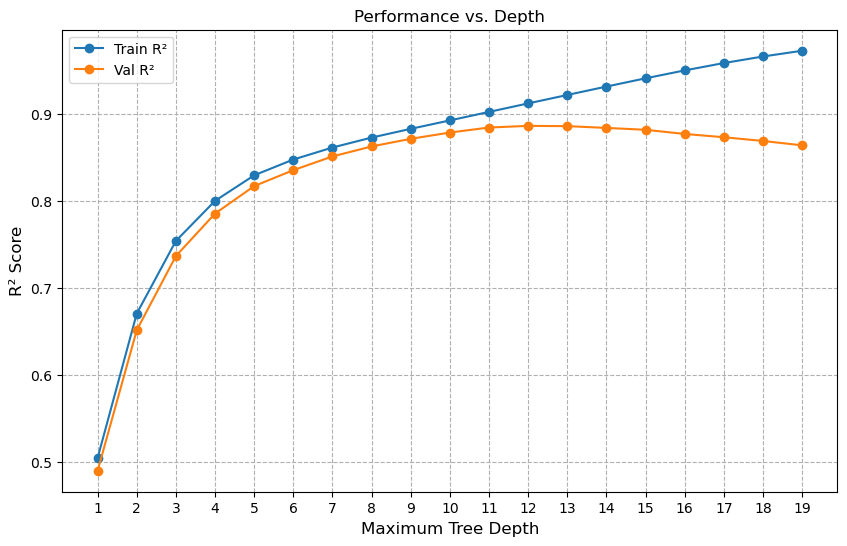

In [28]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [29]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 12


In [30]:
model_four_v2 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_four_v2

,r2,MAPE,MdAPE,MAE
Train Set,0.887775,11.001343,8.084175,$124866.2
Validation Set,0.850043,12.431659,8.944494,$143785.52
Test Set,0.863163,12.039236,8.601768,$143398.93


### Decision Tree Summary

This table presents the best performing model from each section.

| Model | Test r2 | Test MAPE | Test MdAPE | Test MAE |
| ----- | ------- | --------- | ---------- | -------- |
| Model One (Baseline) | 0.859194 | 12.040223 | 8.602571| \$143,806 |
| Model Two (Large Numeric Features Winsorized) | 0.858909 | 12.196823 | 8.856502 | \$145,625 | 
| Model Three (Feature Engineering Additions) | 0.860151 | 12.010818 | 8.598630 | \$143,229 |
| **Model Four (Improved School Districts)** | **0.864478** | **11.885169** | **8.386027** | **\$141,401**|

## Random Forests

In [89]:
x_train = training[common_cols]
y_train = training["ClosePriceLog"]

x_val = validation[common_cols]  
y_val = validation["ClosePriceLog"]

x_test = testing[common_cols]
y_test = testing["ClosePriceLog"]

### Model One: Baseline Random Forest

#### Train Set: January 2024 - February 2026

In [94]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    rf = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

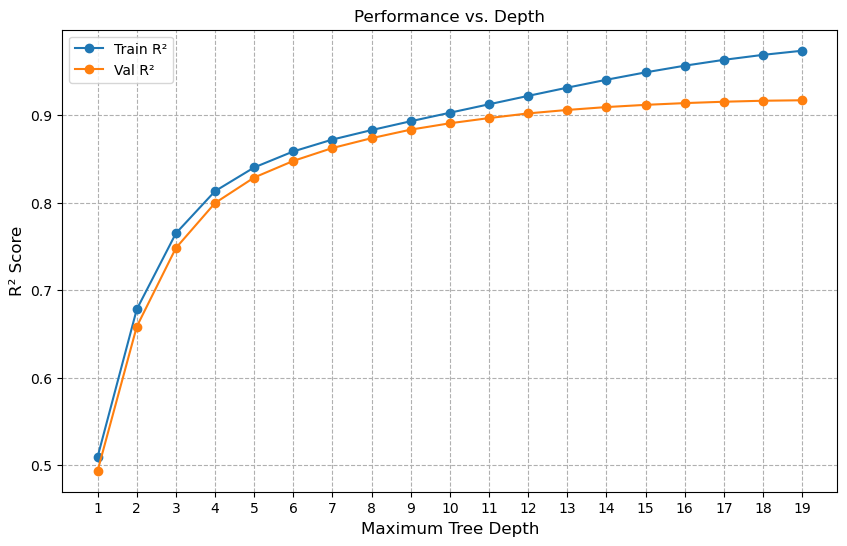

In [95]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [97]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

rf = RandomForestRegressor(n_estimators=100, max_depth=best_depth, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 19


In [98]:
rf_one_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_one_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.966630,6.137130,4.655695,$69473.12
Validation Set,0.886881,10.516910,7.490326,$122686.49
Test Set,0.902327,9.890467,6.873780,$118672.03


#### Train Set: February 2025 - February 2026

In [113]:
common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog",
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "StateOrProvince_AZ", "StateOrProvince_CA",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "PropertyMonth", "ClosePriceLog"]

past_limit = pd.to_datetime("2025-01-01")
present_limit = pd.to_datetime("2026-02-01")

x_train_with_month = training[common_cols]
x_train_with_month.loc[:, "PropertyMonth"] = pd.to_datetime(x_train_with_month["PropertyMonth"])
x_train = x_train_with_month[(x_train_with_month["PropertyMonth"] >= past_limit) & (x_train_with_month["PropertyMonth"] <= present_limit)]
y_train = x_train["ClosePriceLog"]
x_train = x_train.drop(columns = ["PropertyMonth", "ClosePriceLog"])

In [101]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    rf = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

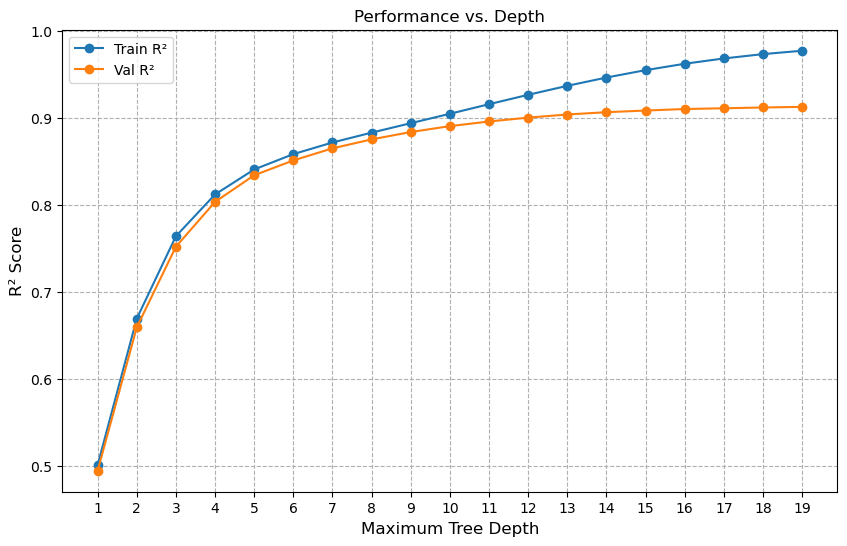

In [102]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [103]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

rf = RandomForestRegressor(n_estimators=100, max_depth=best_depth, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 19


In [104]:
rf_one_v2 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_one_v2

,r2,MAPE,MdAPE,MAE
Train Set,0.970342,5.713106,4.360518,$64524.9
Validation Set,0.880914,10.794509,7.670921,$125931.29
Test Set,0.892360,10.461138,7.492700,$125715.26


#### Train Set: July 2024 - February 2026

In [105]:
# Set the training window to 20 months preceding the validation set

past_limit = pd.to_datetime("2024-06-01")
present_limit = pd.to_datetime("2026-02-01")

x_train_with_month = training[common_cols]
x_train_with_month.loc[:, "PropertyMonth"] = pd.to_datetime(x_train_with_month["PropertyMonth"])
x_train = x_train_with_month[(x_train_with_month["PropertyMonth"] >= past_limit) & (x_train_with_month["PropertyMonth"] <= present_limit)]
y_train = x_train["ClosePriceLog"]
x_train = x_train.drop(columns = ["PropertyMonth", "ClosePriceLog"])

In [106]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    rf = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

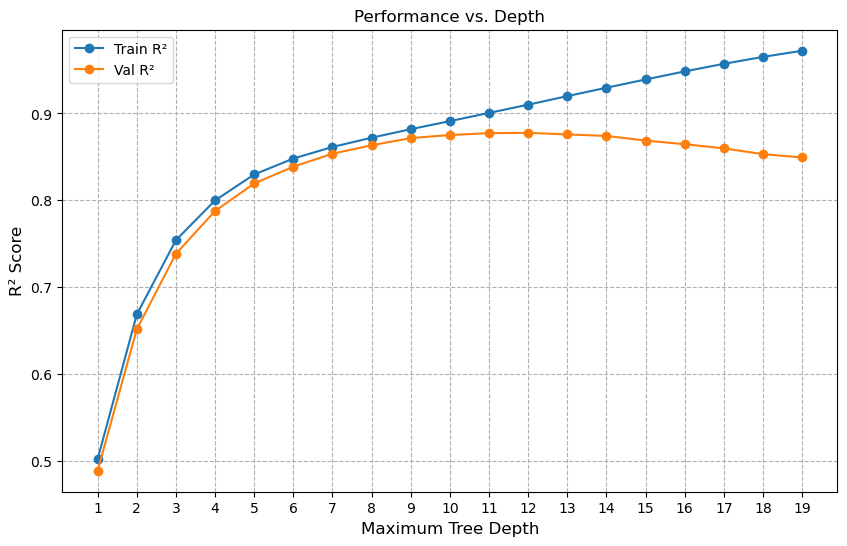

In [107]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [108]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

rf = RandomForestRegressor(n_estimators=100, max_depth=best_depth, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 12


In [109]:
rf_one_v3 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_one_v3

,r2,MAPE,MdAPE,MAE
Train Set,0.900167,10.330682,7.687159,$118156.56
Validation Set,0.867465,11.706381,8.641006,$135842.67
Test Set,0.882707,11.145539,8.173207,$133300.49


### Model Two: Tuning `max_features`

In [124]:
x_train = training[common_cols].drop(columns = ["PropertyMonth", "ClosePriceLog"])
y_train = training["ClosePriceLog"]

x_val = validation[common_cols].drop(columns = ["PropertyMonth", "ClosePriceLog"])
y_val = validation["ClosePriceLog"]

x_test = testing[common_cols].drop(columns = ["PropertyMonth", "ClosePriceLog"])
y_test = testing["ClosePriceLog"]

In [125]:
# The previous model worked very well. It is a good idea now to tune that one further
# Above model used max_features = 1.0 (all features). Try different options for max_features

#max_features = "sqrt"
rf = RandomForestRegressor(n_estimators=100, max_depth=19, random_state=42, n_jobs=-1, max_features = "sqrt")
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

In [126]:
rf_two_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_two_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.952708,6.951193,5.240842,$80560.14
Validation Set,0.875645,10.768767,7.841337,$127416.32
Test Set,0.893383,10.156225,7.341135,$123539.13


In [127]:
# max_features = "log2"
rf = RandomForestRegressor(n_estimators=100, max_depth=19, random_state=42, n_jobs=-1, max_features = "log2")
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

In [128]:
rf_two_v2 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_two_v2

,r2,MAPE,MdAPE,MAE
Train Set,0.952708,6.951193,5.240842,$80560.14
Validation Set,0.875645,10.768767,7.841337,$127416.32
Test Set,0.893383,10.156225,7.341135,$123539.13


### Model Three: Tuning `min_samples_split`

In [130]:
splits = range(2, 11)
train_r2_scores = {}
val_r2_scores = {}

for split in splits:
    rf = RandomForestRegressor(n_estimators=100, max_depth=19, random_state=42, n_jobs=-1, min_samples_split=split)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[split] = train_r2
    val_r2_scores[split] = val_r2

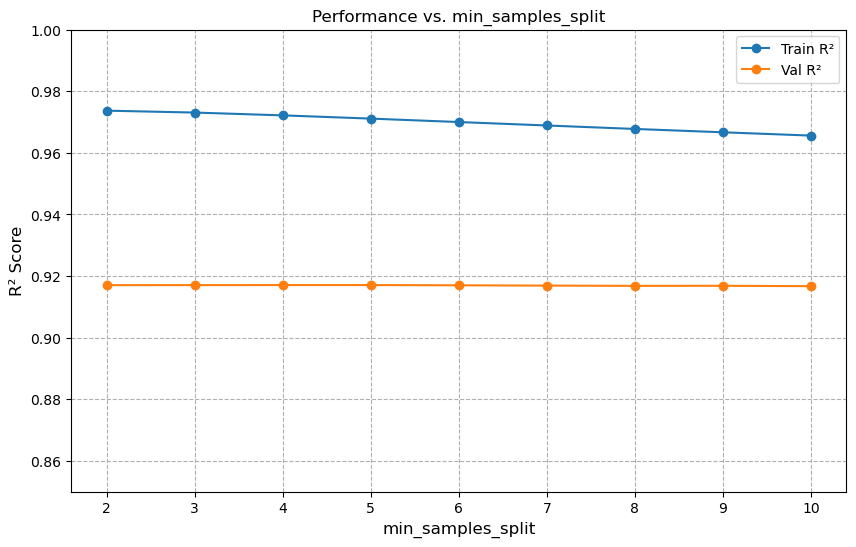

In [134]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("min_samples_split", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. min_samples_split")
plt.xticks(splits)
plt.ylim(0.85, 1) 
plt.grid(True, linestyle="--")
plt.legend()

In [132]:
best_split = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Split: {best_split}")

rf = RandomForestRegressor(n_estimators=100, max_depth=19, random_state=42, n_jobs=-1, min_samples_split=best_split)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Split: 5


In [133]:
rf_three_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_three_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.962872,6.351229,4.741007,$72063.56
Validation Set,0.886867,10.510542,7.484514,$122617.44
Test Set,0.902228,9.893776,6.872347,$118672.13


### Model Four: Tuning `min_samples_leaf`

In [135]:
leaves = range(1, 11)
train_r2_scores = {}
val_r2_scores = {}

for leaf in leaves:
    rf = RandomForestRegressor(n_estimators=100, max_depth=17, random_state=42, n_jobs=-1, min_samples_leaf = leaf)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[leaf] = train_r2
    val_r2_scores[leaf] = val_r2

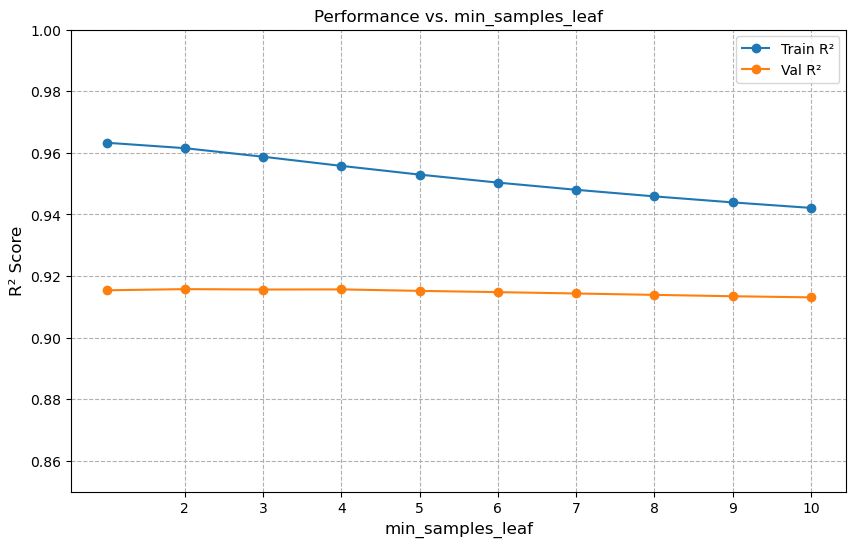

In [137]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("min_samples_leaf", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. min_samples_leaf")
plt.xticks(splits)
plt.ylim(0.85, 1) 
plt.grid(True, linestyle="--")
plt.legend()

In [138]:
best_leaf = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Leaf: {best_leaf}")

rf = RandomForestRegressor(n_estimators=100, max_depth=19, random_state=42, n_jobs=-1, min_samples_leaf = best_leaf)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Leaf: 2


In [139]:
rf_four_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_four_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.962807,6.233841,4.561837,$70719.48
Validation Set,0.887186,10.480918,7.430086,$122366.62
Test Set,0.902728,9.862783,6.853233,$118218.61


### Model Five: BedBathRation and PropertyAge

In [34]:
# In week six, a few features were added to help improve model performance
# Read in the training and test sets created in week six

train_and_val = pd.read_csv("feat_eng_train.csv")
testing = pd.read_csv("feat_eng_test.csv")

In [35]:
training = train_and_val[~(train_and_val["PropertyMonth"] == "2026-03-01")]
validation = train_and_val[train_and_val["PropertyMonth"] == "2026-03-01"]

print(train_and_val.shape, training.shape, validation.shape)

(265314, 163) (255022, 163) (10292, 163)


In [36]:
common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "StateOrProvince_AZ", "StateOrProvince_CA",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "BedBathRatio", "PropertyAge"]

x_train = training[common_cols]
y_train = training["ClosePriceLog"]

x_val = validation[common_cols]  
y_val = validation["ClosePriceLog"]


x_test = testing[common_cols]
y_test = testing["ClosePriceLog"]

In [37]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    rf = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

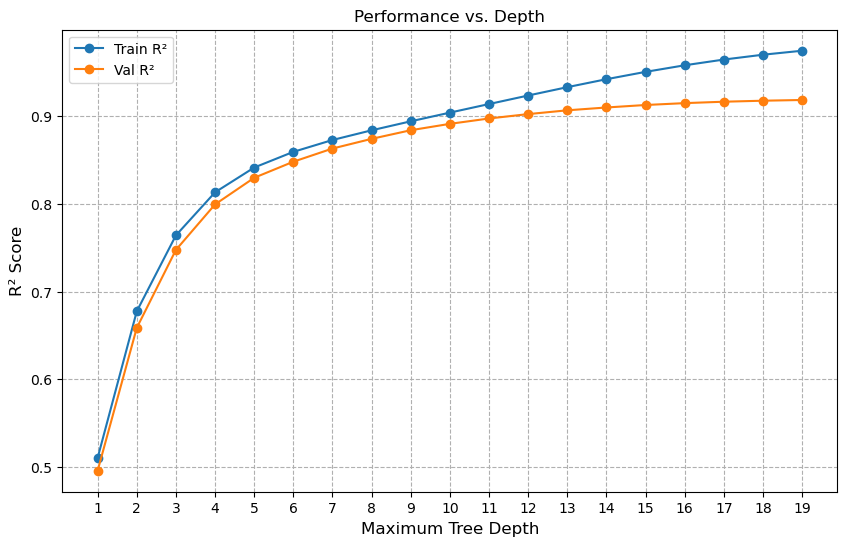

In [38]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

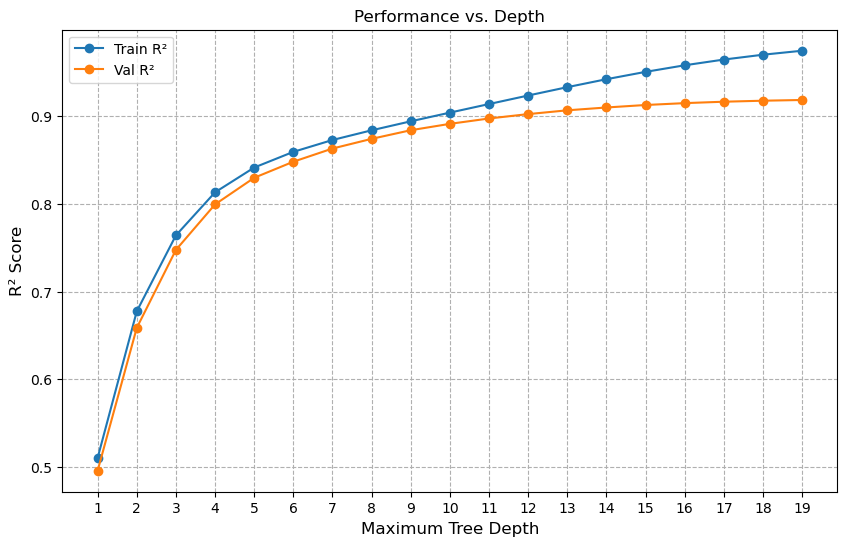

In [39]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [41]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

rf = RandomForestRegressor(n_estimators=100, max_depth=best_depth, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 19


In [42]:
rf_five = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_five

,r2,MAPE,MdAPE,MAE
Train Set,0.967570,6.035040,4.573403,$68425.26
Validation Set,0.888069,10.397598,7.368606,$121593.4
Test Set,0.903329,9.800898,6.843380,$117915.64


### Model Six: Improved School Districts

In [11]:
common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "StateOrProvince_AZ", "StateOrProvince_CA",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "BedBathRatio", "PropertyAge",
            "DistrictName_elem_enc", "DistrictName_unif_enc", "DistrictName_high_enc",
            'EnrollTotal_high', 'EnrollCharter_high', 'EnrollNonCharter_high', 'AApct_high', 'AAcount_high', 'AIpct_high',
            'AIcount_high', 'ASpct_high', 'AScount_high', 'FIpct_high', 'FIcount_high', 'HIpct_high', 'HIcount_high', 'PIpct_high',
            'PIcount_high', 'WHpct_high', 'WHcount_high', 'MRpct_high', 'MRcount_high', 'NRpct_high', 'NRcount_high', 'ELpct_high',
            'ELcount_high', 'FOSpct_high', 'FOScount_high','HOMpct_high','HOMcount_high','MIGpct_high','MIGcount_high','SWDpct_high',
            'SWDcount_high','SEDpct_high','SEDcount_high', 'EnrollTotal_elem','EnrollCharter_elem','EnrollNonCharter_elem','AApct_elem',
            'AAcount_elem','AIpct_elem','AIcount_elem','ASpct_elem','AScount_elem','FIpct_elem','FIcount_elem','HIpct_elem','HIcount_elem',
            'PIpct_elem','PIcount_elem','WHpct_elem','WHcount_elem','MRpct_elem','MRcount_elem','NRpct_elem','NRcount_elem','ELpct_elem',
            'ELcount_elem','FOSpct_elem','FOScount_elem','HOMpct_elem','HOMcount_elem','MIGpct_elem','MIGcount_elem','SWDpct_elem',
            'SWDcount_elem','SEDpct_elem','SEDcount_elem','EnrollTotal_unif','EnrollCharter_unif','EnrollNonCharter_unif','AApct_unif',
            'AAcount_unif','AIpct_unif','AIcount_unif','ASpct_unif','AScount_unif','FIpct_unif','FIcount_unif','HIpct_unif','HIcount_unif',
            'PIpct_unif','PIcount_unif','WHpct_unif','WHcount_unif','MRpct_unif','MRcount_unif','NRpct_unif','NRcount_unif','ELpct_unif',
            'ELcount_unif','FOSpct_unif','FOScount_unif','HOMpct_unif','HOMcount_unif','MIGpct_unif','MIGcount_unif','SWDpct_unif',
            'SWDcount_unif','SEDpct_unif','SEDcount_unif']

x_train = training[common_cols]
y_train = training["ClosePriceLog"]

x_val = validation[common_cols]  
y_val = validation["ClosePriceLog"]

x_test = testing[common_cols]
y_test = testing["ClosePriceLog"]

In [45]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    rf = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

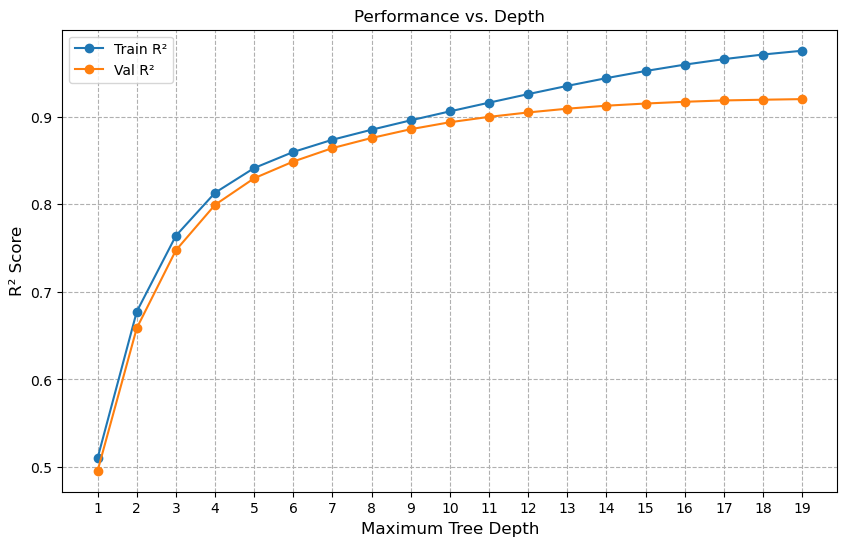

In [46]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [47]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

rf = RandomForestRegressor(n_estimators=100, max_depth=best_depth, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 19


In [48]:
rf_six = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_six

,r2,MAPE,MdAPE,MAE
Train Set,0.968512,5.954562,4.528134,$67453.54
Validation Set,0.890580,10.265929,7.316513,$119975.23
Test Set,0.906585,9.662239,6.749122,$115883.16


### Random Forest Summary

| Model | Test r2 | Test MAPE | Test MdAPE | Test MAE |
| ----- | ------- | --------- | ---------- | -------- |
| Model One | 0.902327 | 9.890467| 6.873780| \$118,672 |
| Model Two | 0.893383| 10.156225 | 7.341135 | \$123,539| 
| Model Three | 0.902228 | 9.893776 | 6.872347 | \$118,672 |
| Model Four | 0.902728 | 9.862783 |  6.853233|  \$118,218|
| Model Five | 0.903329 | 9.800898| 6.843380 | \$117,915 |
| **Model Six** | **0.906585** | **9.662239** | **6.749122** | **\$115,883** |